In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carreguem les dades, els 3 conjunts venen en 3 arxius diferents 
data = pd.read_csv('train (2).csv', on_bad_lines='skip', sep=';')
data_test = pd.read_csv('test (1).csv', on_bad_lines='skip', sep=';')
data_val = pd.read_csv('evaluation.csv', on_bad_lines='skip', sep=';')

print(data[1:10])

   Unnamed: 0                                              title  \
1           1  China says Trump call with Taiwan president wo...   
2           2   FAIL! The Trump Organization’s Credit Score W...   
3           3  Zimbabwe military chief's China trip was norma...   
4           4  THE MOST UNCOURAGEOUS PRESIDENT EVER Receives ...   
5           5  Suspected Boko Haram suicide bombers kill at l...   
6           6  WATCH: John Oliver Presents GOP Debates As ‘Cl...   
7           7  Senate Democrats ask Trump attorney general pi...   
8           8   Trump HUMILIATES Republicans In Latest Hissy ...   
9           9  MACY’S GETS THE BOOT FROM LOYAL CUSTOMERS AFTE...   

                                                text  label  
1  BEIJING (Reuters) - U.S. President-elect Donal...      1  
2  While the controversy over Trump s personal ta...      0  
3  BEIJING (Reuters) - A trip to Beijing last wee...      1  
4  There has never been a more UNCOURAGEOUS perso...      0  
5  BAUCHI

In [4]:
# Calculem la longitud de les noticies
data['word_count'] = data['text'].astype(str).apply(lambda x: len(x.split()))

# Definim les longituds minima i màima de les notícies
min_threshold = 3
max_threshold = 4000

data_filtered = data[(data['word_count'] >= min_threshold) & 
                     (data['word_count'] <= max_threshold)].copy()
print(f"Files eliminadas: {len(data) - len(data_filtered)}")
print(len(data_filtered))

Files eliminadas: 80
24273


# Exploració del conjunt de dades

In [ ]:
print(data.info())
print("\n--- Valors Nuls ---")
print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24353 entries, 0 to 24352
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  24353 non-null  int64 
 1   title       24353 non-null  object
 2   text        24353 non-null  object
 3   label       24353 non-null  int64 
 4   word_count  24353 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 951.4+ KB
None

--- Valors Nuls ---
Unnamed: 0    0
title         0
text          0
label         0
word_count    0
dtype: int64


/tmp/ipykernel_2346892/1445739856.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label_desc', data=data, palette='magma')


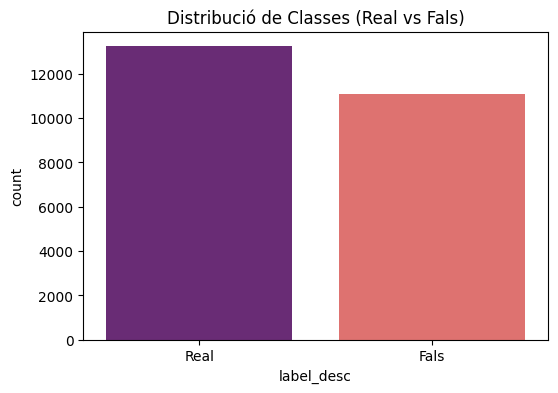

In [6]:
# Plot distribució variable objectiu
data['label_desc'] = data['label'].map({0: 'Fals', 1: 'Real'})
plt.figure(figsize=(6,4))
sns.countplot(x='label_desc', data=data, palette='magma')
plt.title('Distribució de Classes (Real vs Fals)')
plt.show()

/tmp/ipykernel_2346892/1952637257.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='word_count', y='label_desc', data=data, ax=axes[1], palette='magma')


Text(0, 0.5, 'Nombre de paraules')

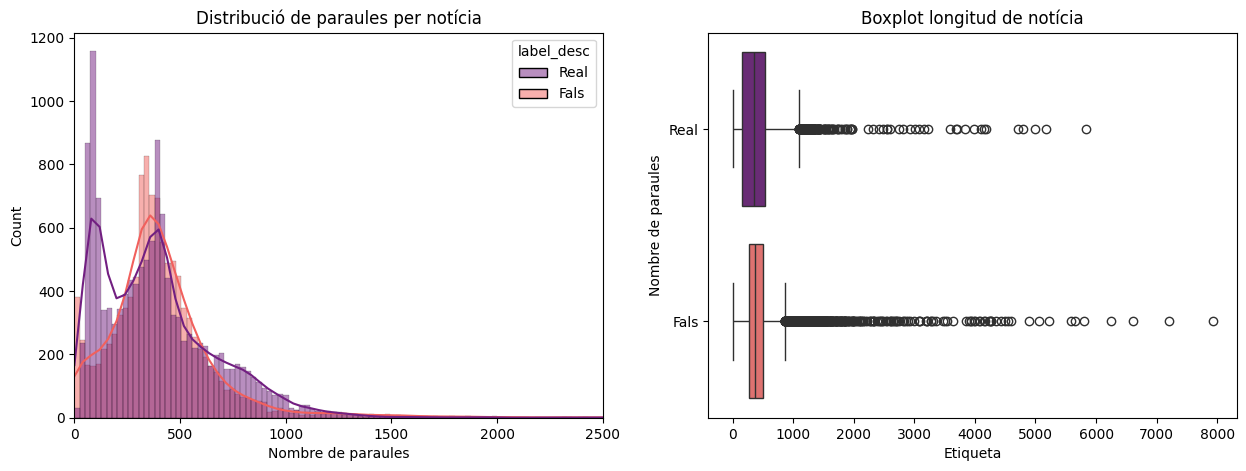

In [7]:
# Anàlisi de longitud del text
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=data, x='word_count', hue='label_desc', kde=True, ax=axes[0], palette='magma')
axes[0].set_title('Distribució de paraules per notícia')
axes[0].set_xlabel('Nombre de paraules')
axes[0].set_xlim(0, 2500)

# Boxplot para detectar outliers
sns.boxplot(x='word_count', y='label_desc', data=data, ax=axes[1], palette='magma')
axes[1].set_title('Boxplot longitud de notícia')
axes[1].set_xlabel('Etiqueta')
axes[1].set_ylabel('Nombre de paraules')

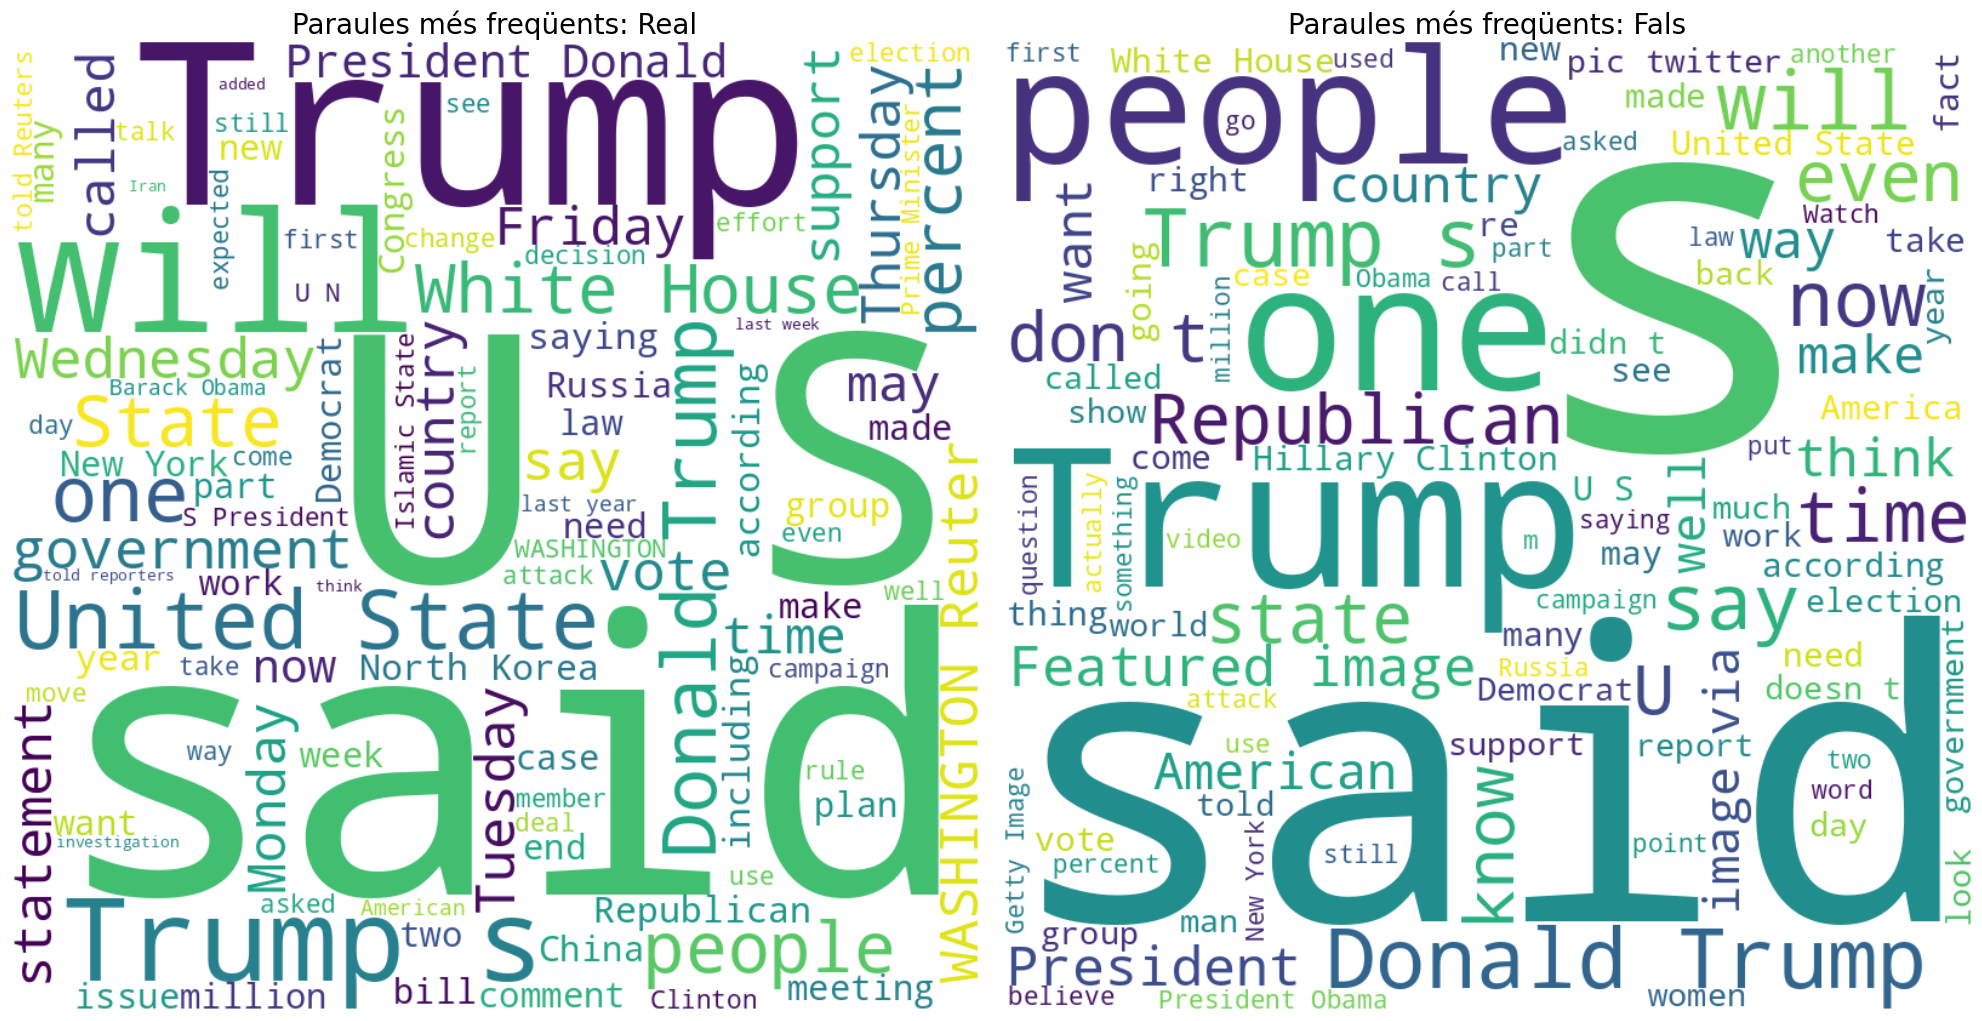

In [ ]:
# WordCloud per veure la distribució de paraules utilitzant el paquet 'WordCloud'
from wordcloud import WordCloud
labels = data['label_desc'].unique()

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

for i, label in enumerate(labels):
    # Filtrem el text per categoria
    subset = data[data['label_desc'] == label]['text'].astype(str)
    text_combined = " ".join(subset)
    
    wc = WordCloud(width=800, height=800, 
                   background_color='white', 
                   max_words=100,
                   colormap='viridis').generate(text_combined)
    
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f"Paraules més freqüents: {label}", fontsize=20)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Neteja base de dades i preprocessament

In [9]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Carreguem les 'stopwords' a l'anglés per eliminarles de les noticies (no aporten valor a les prediccions)
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Definim funció per netejar el text
def clean_text(text):
    # Convertim a minúscules totes les paraules
    text = str(text).lower()
    
    # Eliminem la paraula "reuters" ja que dona massa informació sobre la veracitat d'una noticia i la xarxa no aprendria patrons més complexos
    # Busquem la paraula 'reuters' al principi, seguida d'un guió, i ho borrem tot fins al guió.
    text = re.sub(r'^.*?\breuters\b.*?- ', '', text)
    
    # Eliminem URL's, caràcters d'html (per si s'han obtingut notícies amb web scraping), signes de puntucació i stopwords
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = ' '.join([word for word in text.split() if word not in stop_words])
    
    return text

data['clean_text'] = data['text'].apply(clean_text)
data_test['clean_text'] = data_test['text'].apply(clean_text)
data_val['clean_text'] = data_val['text'].apply(clean_text)


# Definim les variables per poder tokenitzar el text
max_words = 10000  # Mida del vocabulari
max_len = 1500      # Longitud max de la notícia

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(data['clean_text'])

# Convertim el text a seqüències de nombres enters
sequences = tokenizer.texts_to_sequences(data['clean_text'])
sequences_test = tokenizer.texts_to_sequences(data_test['clean_text'])
sequences_eval = tokenizer.texts_to_sequences(data_val['clean_text'])

# Afegim padding per asegurar la mateix longitud a totes les notícies
# Possem el padding al principi per la arquitectura LSTM
X_train = pad_sequences(sequences, maxlen=max_len, padding='pre', truncating='post')
y_train = data['label'].values
X_test = pad_sequences(sequences_test, maxlen=max_len, padding='pre', truncating='post')
y_test = data_test['label'].values
X_val = pad_sequences(sequences_eval, maxlen=max_len, padding='pre', truncating='post')
y_val = data_val['label'].values

print(f"\nEntrenament: {X_train.shape}\nValidació: {X_val.shape}\nTest: {X_test.shape}")

I0000 00:00:1781974495.110177 2346892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1781974495.110600 2346892 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1781974495.139782 2346892 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781974496.005710 2346892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0


Entrenament: (24353, 1500)
Validació: (8117, 1500)
Test: (8117, 1500)


# MLP base amb i sense regularització

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers

VOCAB_SIZE = 10000  # Paraules màximes al vocabolari
MAX_LEN = 1500     # Longitud de notícia maxima
EMBEDDING_DIM = 100 # Dimensió espai d'embeddings
L2 = 0.01

###################MLP SENSE REG###########################################
model_mlp = models.Sequential([
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    layers.GlobalAveragePooling1D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_mlp.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_mlp = model_mlp.fit(
    X_train, y_train,
    epochs=40,
    batch_size=16,
    validation_data=(X_val, y_val)
)

##################MLP AMB REG############################################
model_mlp_reg = models.Sequential([
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    layers.GlobalAveragePooling1D(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(L2)), # Afegim regularització L2
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_mlp_reg.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Regularització implícita 'early stop'
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

history_mlp_reg = model_mlp_reg.fit(
    X_train, y_train,
    epochs=40,
    batch_size=16,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.7451 - loss: 0.4847 - val_accuracy: 0.9207 - val_loss: 0.2297
Epoch 2/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8883 - loss: 0.2735 - val_accuracy: 0.9005 - val_loss: 0.2615
Epoch 3/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9042 - loss: 0.2371 - val_accuracy: 0.8291 - val_loss: 0.4354
Epoch 4/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9056 - loss: 0.2295 - val_accuracy: 0.9430 - val_loss: 0.1780
Epoch 5/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9253 - loss: 0.1890 - val_accuracy: 0.9367 - val_loss: 0.1842
Epoch 6/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9304 - loss: 0.1786 - val_accuracy: 0.9517 - val_loss: 0.1600
Epoch 7/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9285 - loss: 0.1787 - val_accuracy: 0.9517 - val_loss: 0.1532
Epoch 8/40
1523/1523 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9351 - loss: 0

## Plot rendimient

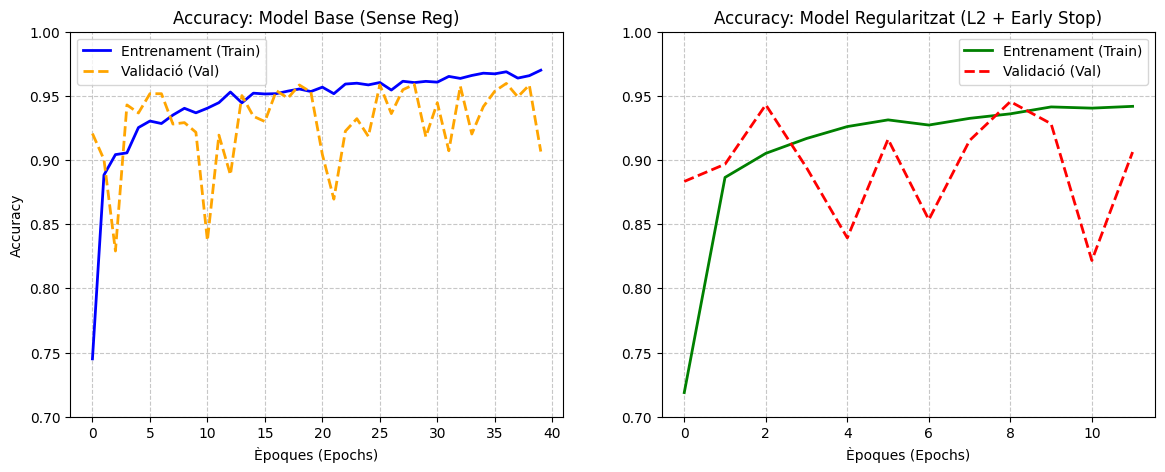

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# GRÀFIC 1: MLP SENSE REG
axs[0].plot(history_mlp.history['accuracy'], label='Entrenament (Train)', color='blue', linewidth=2)
axs[0].plot(history_mlp.history['val_accuracy'], label='Validació (Val)', color='orange', linewidth=2, linestyle='--')
axs[0].set_title('Accuracy: Model Base (Sense Reg)')
axs[0].set_xlabel('Èpoques (Epochs)')
axs[0].set_ylabel('Accuracy')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.7)
# Limitem l'eix Y perquè els dos gràfics tinguin la mateixa escala i siguin comparables
axs[0].set_ylim([0.7, 1.0]) 

# GRÀFIC 2: MLP AMB REG
axs[1].plot(history_mlp_reg.history['accuracy'], label='Entrenament (Train)', color='green', linewidth=2)
axs[1].plot(history_mlp_reg.history['val_accuracy'], label='Validació (Val)', color='red', linewidth=2, linestyle='--')
axs[1].set_title('Accuracy: Model Regularitzat (L2 + Early Stop)')
axs[1].set_xlabel('Èpoques (Epochs)')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.7)
axs[1].set_ylim([0.7, 1.0]) 

plt.show()

254/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
254/254 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


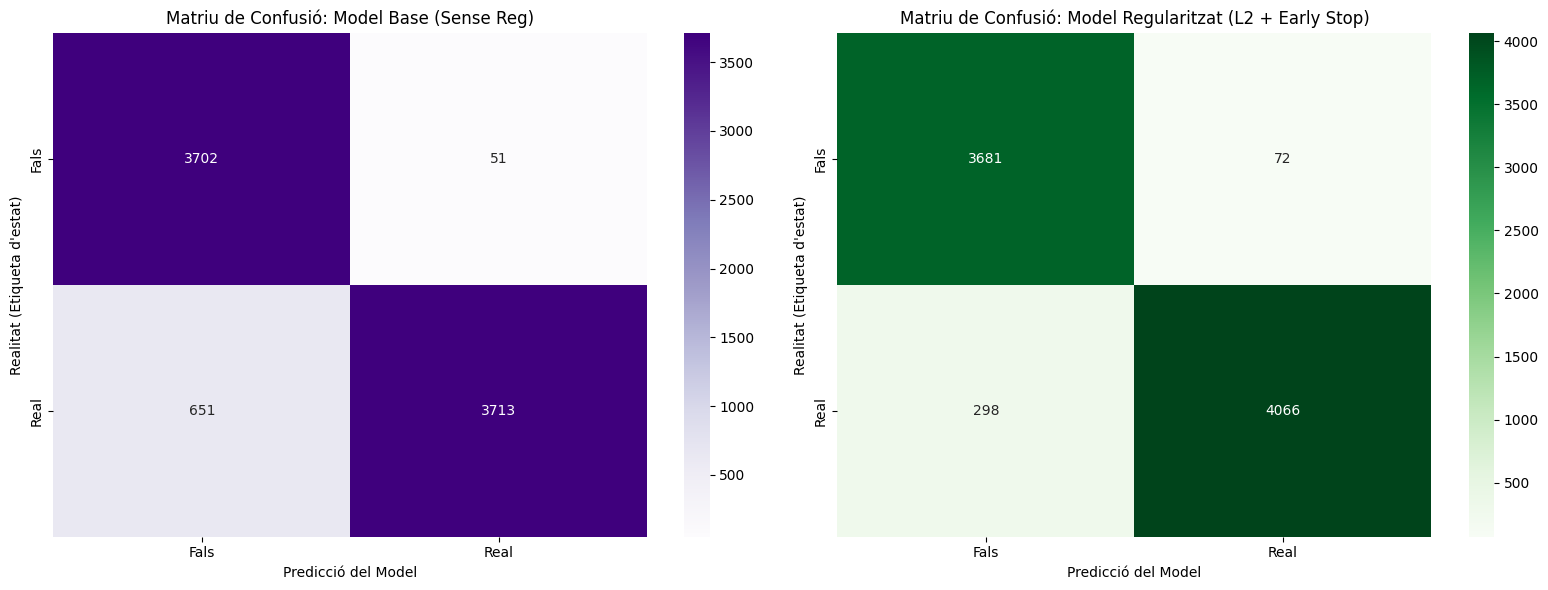

--- Informe de Classificació: Model Base ---
              precision    recall  f1-score   support

        Fals       0.85      0.99      0.91      3753
        Real       0.99      0.85      0.91      4364

    accuracy                           0.91      8117
   macro avg       0.92      0.92      0.91      8117
weighted avg       0.92      0.91      0.91      8117


--- Informe de Classificació: Model Regularitzat ---
              precision    recall  f1-score   support

        Fals       0.93      0.98      0.95      3753
        Real       0.98      0.93      0.96      4364

    accuracy                           0.95      8117
   macro avg       0.95      0.96      0.95      8117
weighted avg       0.96      0.95      0.95      8117



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Fem gràfics i mètriques amb el conjunt de validació
y_pred_prob_base = model_mlp.predict(X_test)
y_pred_base = (y_pred_prob_base > 0.5).astype(int).flatten()

y_pred_prob_reg = model_mlp_reg.predict(X_test)
y_pred_reg = (y_pred_prob_reg > 0.5).astype(int).flatten()

cm_base = confusion_matrix(y_test, y_pred_base)
cm_reg = confusion_matrix(y_test, y_pred_reg)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm_base, annot=True, fmt='d', cmap='Purples', ax=ax1,
            xticklabels=['Fals', 'Real'], yticklabels=['Fals', 'Real'])
ax1.set_title('Matriu de Confusió: Model Base (Sense Reg)')
ax1.set_xlabel('Predicció del Model')
ax1.set_ylabel("Realitat (Etiqueta d'estat)")

sns.heatmap(cm_reg, annot=True, fmt='d', cmap='Greens', ax=ax2,
            xticklabels=['Fals', 'Real'], yticklabels=['Fals', 'Real'])
ax2.set_title('Matriu de Confusió: Model Regularitzat (L2 + Early Stop)')
ax2.set_xlabel('Predicció del Model')
ax2.set_ylabel("Realitat (Etiqueta d'estat)")

plt.tight_layout()
plt.show()

print("Model Base")
print(classification_report(y_test, y_pred_base, target_names=['Fals', 'Real']))

print("\n Model Regularitzat")
print(classification_report(y_test, y_pred_reg, target_names=['Fals', 'Real']))

In [96]:
model_mlp.summary()
model_mlp_reg.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 1500, 100)      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ (None, 100)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,063,749 (11.69 MB)

 Trainable params: 1,021,249 (3.90 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 1500, 100)      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_5      │ (None, 100)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,063,749 (11.69 MB)

 Trainable params: 1,021,249 (3.90 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,042,500 (7.79 MB)

## Plot embeddings t-sne

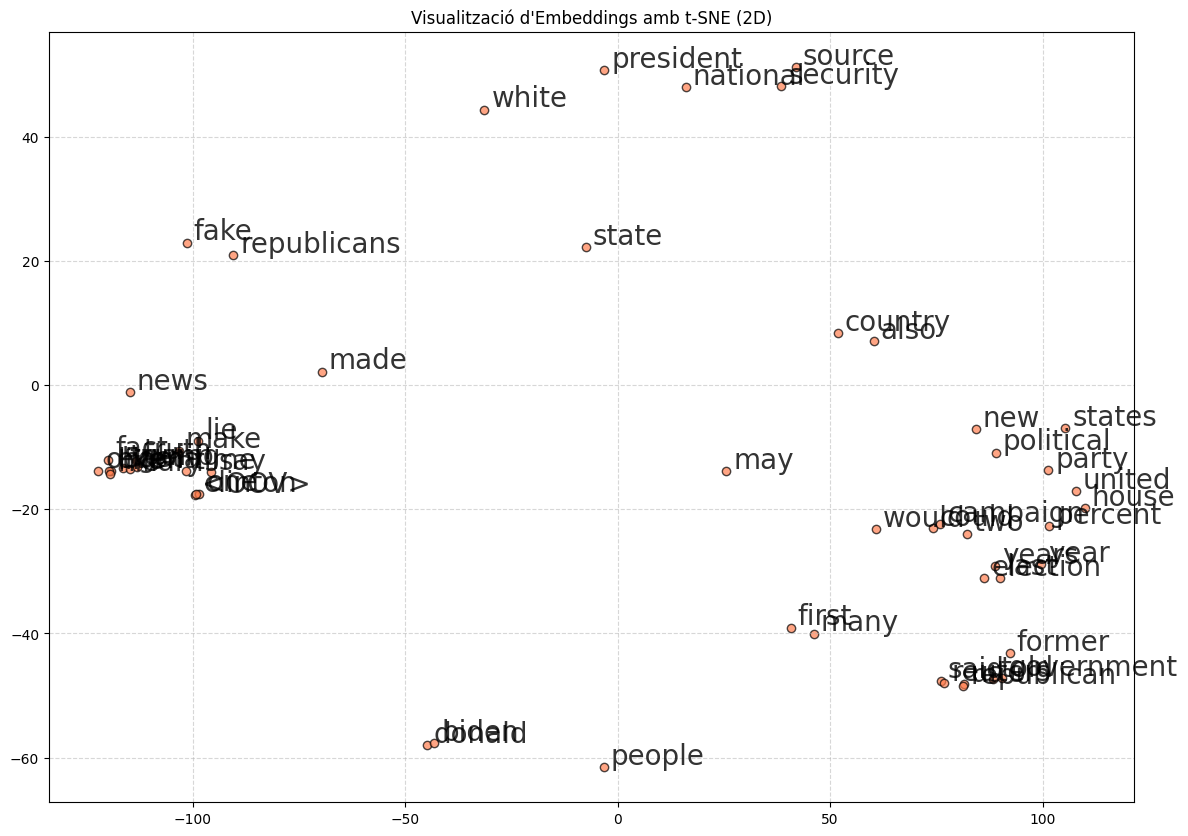

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt


# Plot d'embeddings
weights = model_mlp_reg.layers[0].get_weights()[0]

# Configurel l'algorisme de t-sne
# El paràmetre perplexity indica el nivell d'atenció a les dades locals en relació a les globals (normalment 20-50)
tsne_2d = TSNE(n_components=2, perplexity=30, learning_rate='auto', init='pca', random_state=42)
weights_2d_tsne = tsne_2d.fit_transform(weights)

# Seleccionem les paraules més importants i algunes interessants
top_n = 50
indices_plot = list(range(1, top_n))
palabras_clave = ['fake', 'reuters', 'trump', 'biden', 'lie', 'truth', 'fact', 'source']

for word in palabras_clave:
    if word in tokenizer.word_index:
        idx = tokenizer.word_index[word]
        if idx < VOCAB_SIZE and idx not in indices_plot:
            indices_plot.append(idx)

# Gràfic
plt.figure(figsize=(14, 10))
plt.scatter(weights_2d_tsne[indices_plot, 0], weights_2d_tsne[indices_plot, 1], 
            alpha=0.7, c='coral', edgecolors='k')

for i in indices_plot:
    plt.annotate(tokenizer.index_word[i],
                 xy=(weights_2d_tsne[i, 0], weights_2d_tsne[i, 1]),
                 xytext=(5, 2),
                 textcoords='offset points',
                 fontsize=20,
                 alpha=0.8)

plt.title('Visualització d\'Embeddings amb t-SNE (2D)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Arquitectura con Glove y LSTM

In [ ]:
# Descarreguem la capa d'embeddings de Glove
!wget http://nlp.stanford.edu/data/glove.6B.zip
!unzip -q glove.6B.zip

--2026-06-08 14:22:40--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-06-08 14:22:41--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-06-08 14:22:42--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [10]:
# llegim l'arxiu per carregar la capa a un objecte

path_to_glove_file = "glove.6B.100d.txt"

embeddings_index = {}
with open(path_to_glove_file, encoding="utf-8") as f:
    for line in f:
        word, coefs = line.split(maxsplit=1)
        coefs = np.fromstring(coefs, "f", sep=" ")
        embeddings_index[word] = coefs

In [ ]:
embedding_matrix = np.zeros((VOCAB_SIZE, EMBEDDING_DIM))

hits = 0
misses = 0

# Busquem les paraules del nostre diccionari a les del de Glove, les que trobem les afegim a la matriu d'embeddings
for word, i in tokenizer.word_index.items():
    if i >= VOCAB_SIZE:
        continue
        
    embedding_vector = embeddings_index.get(word)
    
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector
        hits += 1
    else:
        misses += 1

print(f"Paraules convertides (Hits): {hits}")
print(f"Paraules no trobades (Misses): {misses}")

Paraules convertides (Hits): 9778
Paraules no trobades (Misses): 221


In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers

# Construim el model LSTM
L2_RATE = 0.01

model_lstm_l2 = models.Sequential([
    
    # Capa d'embedding de Glove
    layers.Embedding(
        input_dim=VOCAB_SIZE, 
        output_dim=EMBEDDING_DIM, 
        weights=[embedding_matrix], 
        input_length=MAX_LEN,
        trainable=False 
    ),
    
    # Capa LSTM bidireccional (llegeix el text de principi a final i de final a principi)
    layers.Bidirectional(
        layers.LSTM(
            64, 
            return_sequences=False, # Només ens quedem amb l'ultim vector de la seqüència, que es una combinació de totes les paraules
            kernel_regularizer=regularizers.l2(L2_RATE) # Regularització L2
        )
    ),
    
    # Capes per classificació dels vectors de sortida de la LSTM
    layers.Dense(
        32, 
        activation='relu',
        kernel_regularizer=regularizers.l2(L2_RATE)
    ),    
    layers.Dense(1, activation='sigmoid') 
])

model_lstm_l2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_lstm_l2.summary()

early_stop = callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

history_lstm_l2 = model_lstm_l2.fit(
    X_train, y_train,
    epochs=30,
    batch_size=64, 
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

/home/pol/python_envs/myenv/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:103: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
E0000 00:00:1781974596.302276 2346892 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,000,000 (3.81 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,000,000 (3.81 MB)

Epoch 1/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 161s 417ms/step - accuracy: 0.8940 - loss: 0.7802 - val_accuracy: 0.9109 - val_loss: 0.3180
Epoch 2/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 153s 402ms/step - accuracy: 0.9065 - loss: 0.3185 - val_accuracy: 0.8943 - val_loss: 0.3527
Epoch 3/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 149s 392ms/step - accuracy: 0.8827 - loss: 0.3763 - val_accuracy: 0.9129 - val_loss: 0.3063
Epoch 4/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 153s 403ms/step - accuracy: 0.9238 - loss: 0.2708 - val_accuracy: 0.9358 - val_loss: 0.2343
Epoch 5/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 159s 417ms/step - accuracy: 0.9188 - loss: 0.2704 - val_accuracy: 0.9258 - val_loss: 0.2488
Epoch 6/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 165s 432ms/step - accuracy: 0.9225 - loss: 0.2519 - val_accuracy: 0.9316 - val_loss: 0.2315
Epoch 7/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 165s 433ms/step - accuracy: 0.9042 - loss: 0.3030 - val_accuracy: 0.9021 - val_loss: 0.2926
Epoch 8/30
381/381 ━━━━━━━━━━━━━━━━━━━━ 166s 437ms/step - accuracy: 0.9257 -

## Fine tunning

In [15]:
# Descongelem la capa d'embeddings
model_lstm_l2.layers[0].trainable = True

model_lstm_l2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5), # Learning rate molt petit (0.00005)
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Només entrenem 3 èpoques
history_finetune = model_lstm_l2.fit(
    X_train, y_train, epochs=3, batch_size=64, validation_data=(X_val, y_val)
)

Epoch 1/3
381/381 ━━━━━━━━━━━━━━━━━━━━ 207s 538ms/step - accuracy: 0.9632 - loss: 0.1336 - val_accuracy: 0.9580 - val_loss: 0.1430
Epoch 2/3
381/381 ━━━━━━━━━━━━━━━━━━━━ 209s 548ms/step - accuracy: 0.9637 - loss: 0.1306 - val_accuracy: 0.9584 - val_loss: 0.1418
Epoch 3/3
381/381 ━━━━━━━━━━━━━━━━━━━━ 208s 547ms/step - accuracy: 0.9643 - loss: 0.1291 - val_accuracy: 0.9587 - val_loss: 0.1407


In [16]:
model_lstm_l2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 1500, 100)      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,265,925 (12.46 MB)

 Trainable params: 1,088,641 (4.15 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,177,284 (8.31 MB)

# DIAGNÒSTIC LSTM

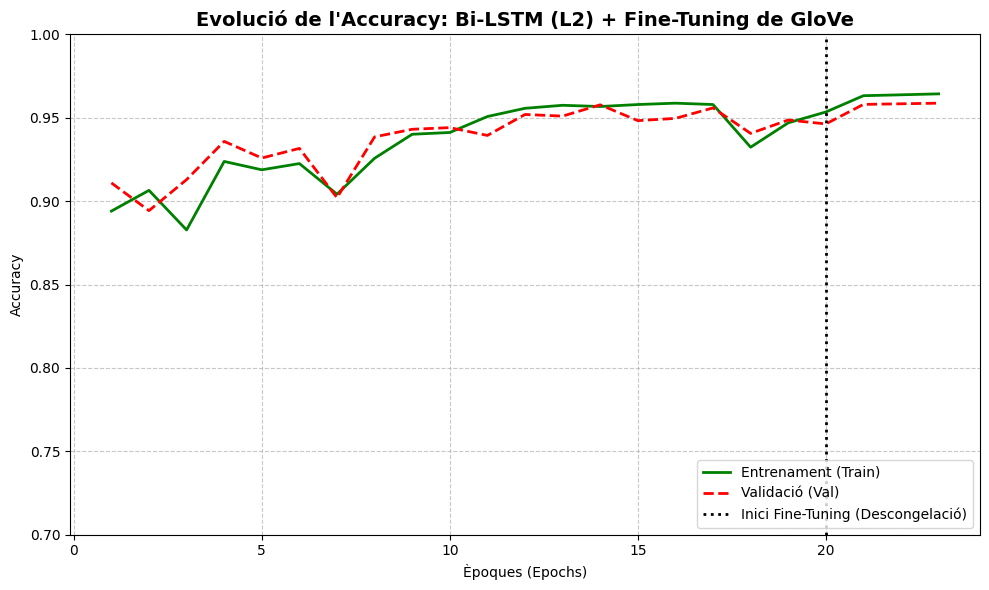

In [17]:
import matplotlib.pyplot as plt

acc = history_lstm_l2.history['accuracy'] + history_finetune.history['accuracy']
val_acc = history_lstm_l2.history['val_accuracy'] + history_finetune.history['val_accuracy']

fase1_epochs = len(history_lstm_l2.history['accuracy'])
total_epochs = len(acc)

epochs_range = range(1, total_epochs + 1)

# Gràfic corves d'aprenentatge
plt.figure(figsize=(10, 6))

plt.plot(epochs_range, acc, label='Entrenament (Train)', color='green', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validació (Val)', color='red', linewidth=2, linestyle='--')

# línia de fine tunning
plt.axvline(x=fase1_epochs, color='black', linestyle=':', linewidth=2, label='Inici Fine-Tuning (Descongelació)')

plt.title("Evolució de l'Accuracy: Bi-LSTM (L2) + Fine-Tuning de GloVe", fontsize=14, fontweight='bold')
plt.xlabel('Èpoques (Epochs)')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.ylim([0.7, 1.0]) # Mantenim la teva escala per poder comparar amb el MLP

# Mostrem el resultat
plt.tight_layout()
plt.show()

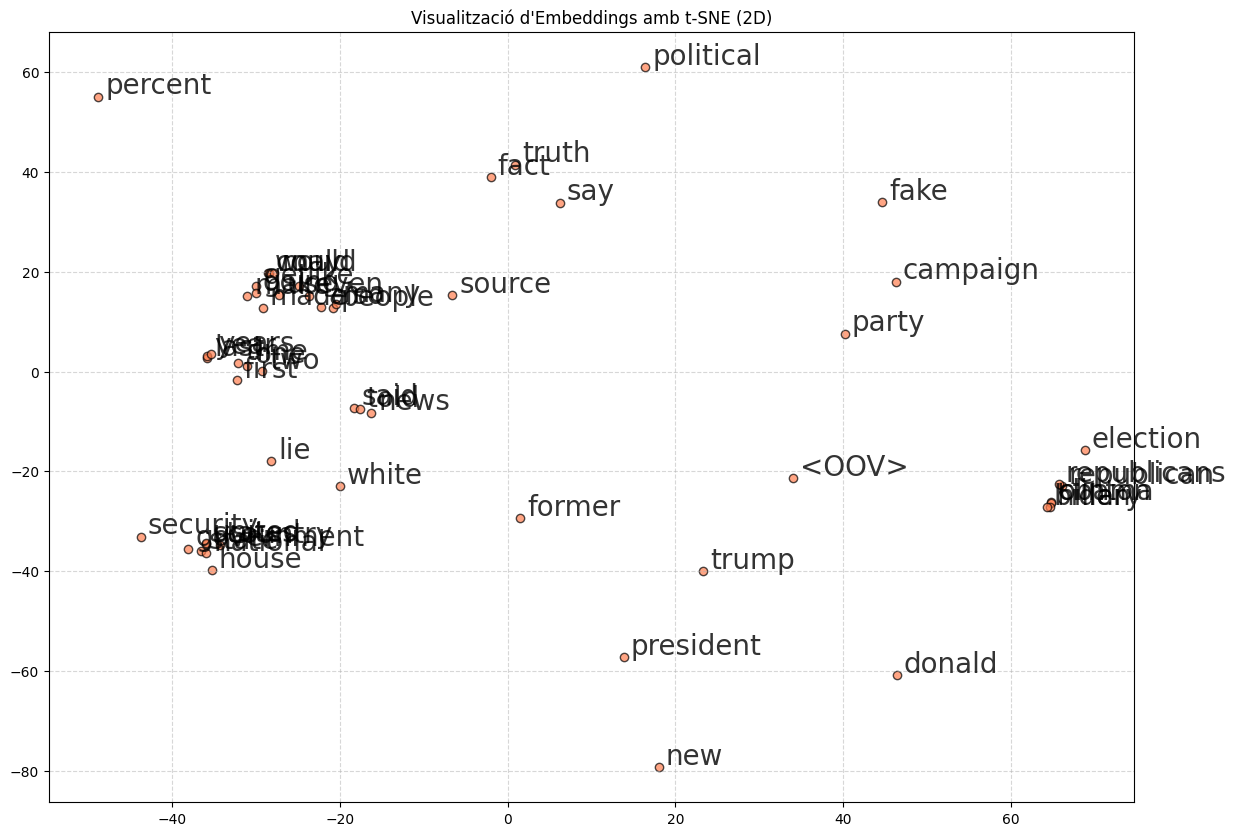

In [ ]:
# Tornem a fer gràfic d'embeddings amb les mateixes configuracions de t-sne d'abans
weights = model_lstm_l2.layers[0].get_weights()[0]

tsne_2d = TSNE(n_components=2, perplexity=30, learning_rate='auto', init='pca', random_state=42)
weights_2d_tsne = tsne_2d.fit_transform(weights)

top_n = 50
indices_plot = list(range(1, top_n))
palabras_clave = ['fake', 'trump', 'biden', 'lie', 'truth', 'fact', 'source']

for word in palabras_clave:
    if word in tokenizer.word_index:
        idx = tokenizer.word_index[word]
        if idx < VOCAB_SIZE and idx not in indices_plot:
            indices_plot.append(idx)

plt.figure(figsize=(14, 10))
plt.scatter(weights_2d_tsne[indices_plot, 0], weights_2d_tsne[indices_plot, 1], 
            alpha=0.7, c='coral', edgecolors='k')

for i in indices_plot:
    plt.annotate(tokenizer.index_word[i],
                 xy=(weights_2d_tsne[i, 0], weights_2d_tsne[i, 1]),
                 xytext=(5, 2),
                 textcoords='offset points',
                 fontsize=20,
                 alpha=0.8)

plt.title('Visualització d\'Embeddings amb t-SNE (2D)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [30]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_pred_prob = model_lstm_l2.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()


cm = confusion_matrix(y_test, y_pred)

print("Model LSTM")
print(classification_report(y_test, y_pred, target_names=['Fals', 'Real']))

254/254 ━━━━━━━━━━━━━━━━━━━━ 15s 60ms/step
Model LSTM
              precision    recall  f1-score   support

        Fals       0.96      0.97      0.96      3753
        Real       0.98      0.96      0.97      4364

    accuracy                           0.97      8117
   macro avg       0.97      0.97      0.97      8117
weighted avg       0.97      0.97      0.97      8117



In [ ]:
# Creem textos per avaluar LSTM
texto_veraz = "The Pentagon confirmed that it is a completely false rumor about an imminent attack. No troops are going to be deployed."
texto_fake = "The Pentagon confirmed a rumor about an imminent attack. It is completely false that no troops are going to be deployed."

In [ ]:
# Funció per fer prediccions de notícies

def predir_noticia(text_noticia):
    text_net = clean_text(text_noticia)
    seq = tokenizer.texts_to_sequences([text_net])
    padd = pad_sequences(seq, maxlen=1500, padding='pre', truncating='post')
    prediccio = model_lstm_l2.predict(padd)
    probabilitat = prediccio[0][0]
    resultat = "REAL" if probabilitat > 0.5 else "FALS"
    
    print(f"Resultat: {resultat}")
    print(f"Confiança: {probabilitat if resultat == 'REAL' else 1 - probabilitat:.2%}")

text = texto_fake
predir_noticia(text)

pentagon confirmed rumor imminent attack completely false troops going deployed
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
Resultat: FALS
Confiança: 67.18%


# Model clàssic

In [26]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Tokenització de les paraules amb TF-IDF
vectorizer = TfidfVectorizer(max_features=10000) 

X_train_tfidf = vectorizer.fit_transform(data["clean_text"])
X_val_tfidf = vectorizer.transform(data_val["clean_text"])

# Definim model de regressió logísitca
model_lr = LogisticRegression(max_iter=500, random_state=42)
model_lr.fit(X_train_tfidf, data["label"])

y_pred_lr = model_lr.predict(X_val_tfidf)

# Mètriques del model
print("Model regressió logística")
print(classification_report(data_val["label"], y_pred_lr, target_names=['Fals', 'Real']))

Model regressió logística
              precision    recall  f1-score   support

        Fals       0.96      0.96      0.96      3803
        Real       0.96      0.97      0.96      4314

    accuracy                           0.96      8117
   macro avg       0.96      0.96      0.96      8117
weighted avg       0.96      0.96      0.96      8117



## Estratègia d'ensemble

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score

prob_nn = model_lstm_l2.predict(X_val).flatten()

prob_lr = model_lr.predict_proba(X_val_tfidf)[:, 1]

best_alpha = 0.5
best_acc = 0.0

# llista possibles valors alpha
alphas = np.linspace(0, 1, 21)

resultats_alpha = []

for alpha in alphas:
    prob_ens = (alpha * prob_nn) + ((1 - alpha) * prob_lr)
    
    y_pred_ens = (prob_ens > 0.5).astype(int)
    acc = accuracy_score(y_val, y_pred_ens)
    
    resultats_alpha.append(acc)
    
    if acc > best_acc:
        best_acc = acc
        best_alpha = alpha

print(f"Millor alpha: {best_alpha:.2f}")
print(f"Accuracy màxim en Validació: {best_acc:.4f}\n")

# Model ensemble final
prob_ensemble_opt = (best_alpha * prob_nn) + ((1 - best_alpha) * prob_lr)
y_pred_ensemble_opt = (prob_ensemble_opt > 0.5).astype(int)

print("Ensemble:")
print(classification_report(y_val, y_pred_ensemble_opt, target_names=['Fals', 'Real']))

254/254 ━━━━━━━━━━━━━━━━━━━━ 17s 68ms/step
-> Millor pes per a la Xarxa Neuronal (alpha): 0.30
-> Millor pes per a la Regressió Logística:   0.70
-> Accuracy màxim en Validació:                 0.9677

Report de Classificació de l'Ensemble Optimitzat:
              precision    recall  f1-score   support

        Fals       0.96      0.97      0.97      3803
        Real       0.97      0.97      0.97      4314

    accuracy                           0.97      8117
   macro avg       0.97      0.97      0.97      8117
weighted avg       0.97      0.97      0.97      8117



# Resultats model final al conjunt test

In [ ]:
X_test_tfidf = vectorizer.transform(data_test["clean_text"])

prob_nn_test = model_lstm_l2.predict(X_test).flatten()
prob_lr_test = model_lr.predict_proba(X_test_tfidf)[:, 1]
prob_ensemble_test = (best_alpha * prob_nn_test) + ((1 - best_alpha) * prob_lr_test)

y_pred_ensemble_test = (prob_ensemble_test > 0.5).astype(int)

acc_test = accuracy_score(y_test, y_pred_ensemble_test)

print(f"\n  Accuracy model final: {acc_test:.4f}\n")

print("Model final:")
print(classification_report(y_test, y_pred_ensemble_test, target_names=['Fals', 'Real']))

254/254 ━━━━━━━━━━━━━━━━━━━━ 16s 62ms/step

▶ Accuracy Final de l'Ensemble (TEST): 0.9715

Report de Classificació Final (TEST):
              precision    recall  f1-score   support

        Fals       0.97      0.97      0.97      3753
        Real       0.98      0.97      0.97      4364

    accuracy                           0.97      8117
   macro avg       0.97      0.97      0.97      8117
weighted avg       0.97      0.97      0.97      8117



In [41]:
import numpy as np

y_test_np = np.array(y_test)
y_pred_np = np.array(y_pred_ensemble_test).flatten()
tittle_test_np = np.array(data_test['title'])
text_test_np = np.array(data_test['text'])

prob_test_np = np.array(prob_ensemble_test).flatten()

# Falsos positius
fp_mask = (y_pred_np == 1) & (y_test_np == 0)
fp_indices = np.where(fp_mask)[0]

# Falsos negatius
fn_mask = (y_pred_np == 0) & (y_test_np == 1)
fn_indices = np.where(fn_mask)[0]

print(f"Total Falsos Positius: {len(fp_indices)}")
print(f"Total Falsos Negatius: {len(fn_indices)}\n")

# Funció per veure els casos
def imprimir_casos(indices, tipo_error, prob_array, num_casos=3):
    print(f"=============== {tipo_error.upper()} ===============")
    for idx in indices[:num_casos]:
        print(f"- Índex en el test set: {idx}")
        prob = prob_array[idx] * 100
        print(f"Probabilitat predita: {prob:.2f}%")
        print(f"Títol: {tittle_test_np[idx]}")
        # Imprimim només els primers 800 caràcters
        text_preview = text_test_np[idx][:800] 
        print(f"Text:\n{text_preview}...\n")
        print("-" * 70)

# Cridem a la funció passant-li 'prob_test_np'
imprimir_casos(fp_indices, "Falsos Positius", prob_test_np, num_casos=4)
imprimir_casos(fn_indices, "Falsos Negatius", prob_test_np, num_casos=4)

Total Falsos Positius: 102
Total Falsos Negatius: 129

=============== FALSOS POSITIUS ===============
- Índex en el test set: 22
Probabilitat predita: 67.24%
Títol: NEW LAW WILL PUNISH MUSLIM Migrants…Assimilate Or Get Out!
Text:
Is this common sense law even practical given how many Muslims migrants with ties to terrorism have already embedded themselves in communities across Europe. The mass sexual assaults and rapes that took place on New Years Eve in Germany should be a pretty good indicator of how interested these male Muslim migrants are in assimilating.  German Chancellor Angela Merkel s ruling coalition agreed Thursday on tough measures to spur the integration of migrants and refugees, including sanctions for failing to take part in programs such as language classes.The deal, hammered out in six hours of late-night talks between Merkel s conservative Christian Union bloc and the Social Democrats (SPD), also included plans for new anti-terror legislation. Now that hundreds of t